# Playoff, title and flush odds: are they calibrated?

The app's season simulation (`src/engine/sim.ts`) says things like "62% to make the playoffs". This notebook checks whether those
numbers match what happens, by replaying finished seasons week by week.

**The model under test** (ported below, same rules as the app):

* every remaining regular-season game: each team scores Normal(best-lineup expected points, team weekly SD), the higher score wins;
  games of the current week use SD × 0.85, as in the app;
* final table ranked by `wins × 10000 + points for`; seeding: division winners first, then wildcards by the same key;
* playoffs (`bracket/season.ts`): the standard bracket with byes for the top seeds, higher score advances (two-week rounds add up);
  the non-playoff teams play a **toilet bowl** seeded worst-first where the **lower** score advances; its last team standing is the
  "flush" (the league's worst team).

**The replay.** For each league and each regular-season week `w` (0 = before week 1), the notebook stands where the app would
stand after week `w`: records and points-for through week `w`, every roster as it was in week `w`, and the projections for the rest of
the season. It records each team's predicted playoff, title and flush chance and compares them with what happened.

**What "only data through week w" can and cannot mean here.** Sleeper's projection endpoint returns, for a past week, the projection
as it stood just before that week was played. Nobody can fetch what the projection for week 12 looked like back in week 5. So the
replay runs two versions that bracket the truth:

* **oracle**: the real per-week projection for every future week. It knows about future injuries, bye weeks and role changes the app
  could not have known at week `w`, so it is a little *better informed* than the app was.
* **carried forward**: each player's latest projection as of week `w + 1` (his most recent positive one, if he was out that week), used
  for every later week in which his NFL team plays. No future information, but cruder than the app's real future-week projections.

Rosters are frozen at week `w` in both, so later trades and pickups are unknown, which is also true of the app at the time.

## Data: Sleeper's public API, cached on disk

Every request goes through `get()`, which keeps a gzipped copy under `notebooks/.cache/sleeper/` (git-ignored). All seasons used
here are finished, so a cached response never goes stale. The first run downloads a few thousand small files (a few minutes
under Sleeper's rate limit); later runs read the cache.

**Which leagues.** The owner's own finished league is *goon squad* (2025, 8 teams). It has 8 playoff spots for 8 teams, so every
team makes the playoffs and it says nothing about playoff odds; it still counts for title and flush odds. No other finished
league is reachable from the owner's account: the members of both of the owner's leagues play in no other Sleeper league.
To get enough seasons, the notebook widens the net from two **public example leagues** that the open-source `ffscrapr` R package
uses in its documentation (league ids `522458773317046272` and `521379020332068864`). It takes their members' 2023-2025 leagues and
keeps the ordinary ones:

* finished (`status == complete`), head-to-head (no best ball, no extra game against the league median),
* 8 to 14 teams, fewer playoff spots than teams, playoffs starting in week 14-16,
* offense-only lineups (no IDP slots, which the projections here do not cover).

Only aggregate numbers are reported. Apart from the owner's own league, league names, team names and usernames are never printed; other leagues are shown as a short hash.

In [1]:
import gzip, hashlib, json, time, urllib.request, urllib.error
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, pandas as pd

CACHE = Path('.cache') / 'sleeper'
CACHE.mkdir(parents=True, exist_ok=True)
BASE = 'https://api.sleeper.app'

def get(path):
    """GET a Sleeper path (e.g. '/v1/league/123'), cached forever on disk. Returns None on a 404."""
    f = CACHE / (hashlib.sha1(path.encode()).hexdigest()[:20] + '.json.gz')
    if f.exists():
        with gzip.open(f, 'rt') as fh: return json.load(fh)
    for attempt in range(5):
        try:
            with urllib.request.urlopen(BASE + path, timeout=30) as r:
                data = json.load(r)
            break
        except urllib.error.HTTPError as e:
            if e.code == 404: data = None; break
            time.sleep(1 + 2 * attempt)
        except Exception:
            time.sleep(1 + 2 * attempt)
    else:
        raise RuntimeError('failed: ' + path)
    with gzip.open(f, 'wt') as fh: json.dump(data, fh)
    return data

def get_many(paths, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(get, paths))

anon = lambda lid: hashlib.sha1(str(lid).encode()).hexdigest()[:6]

OWNER_USER = '1270089224720232448'
OWNER_LEAGUE_2025 = '1270085638657413120'           # goon squad
PUBLIC_SEEDS = ['522458773317046272', '521379020332068864']
SEASONS = ['2023', '2024', '2025']
OFFENSE_SLOTS = {'QB', 'RB', 'WR', 'TE', 'K', 'DEF', 'FLEX', 'SUPER_FLEX', 'REC_FLEX', 'WRRB_FLEX'}
NON_LINEUP = {'BN', 'IR', 'TAXI'}

def ordinary(l):
    s = l.get('settings') or {}
    slots = [p for p in l.get('roster_positions') or [] if p not in NON_LINEUP]
    n, P = l.get('total_rosters') or 0, s.get('playoff_teams') or 6
    return (l.get('status') == 'complete' and not s.get('best_ball') and not s.get('league_average_match')
            and 8 <= n <= 14 and P < n and 14 <= (s.get('playoff_week_start') or 15) <= 16
            and all(x in OFFENSE_SLOTS for x in slots) and s.get('type', 0) in (0, 1, 2))

owner_leagues = get(f'/v1/user/{OWNER_USER}/leagues/nfl/2025') or []
members = sorted({u['user_id'] for lid in PUBLIC_SEEDS for u in (get(f'/v1/league/{lid}/users') or [])})
found = {}
for lists in get_many([f'/v1/user/{u}/leagues/nfl/{y}' for u in members for y in SEASONS]):
    for l in lists or []: found[l['league_id']] = l
ext = sorted((l for l in found.values() if ordinary(l)), key=lambda l: (l['season'], l['league_id']))
print('owner 2025 leagues:', [(l['name'], l['total_rosters'], l['settings'].get('playoff_teams')) for l in owner_leagues])
print(f'public-seed members: {len(members)}, their 2023-25 leagues: {len(found)}, ordinary: {len(ext)}')
print(pd.Series([l['season'] for l in ext]).value_counts().sort_index().to_dict())

owner 2025 leagues: [('goon squad', 8, 8)]
public-seed members: 24, their 2023-25 leagues: 177, ordinary: 106
{'2023': 42, '2024': 35, '2025': 29}


In [2]:
def load_league(lid):
    lg = get(f'/v1/league/{lid}')
    s = lg['settings']
    last = 18 if int(lg['season']) >= 2021 else 17
    weeks = list(range(1, last + 1))
    mups = get_many([f'/v1/league/{lid}/matchups/{w}' for w in weeks])
    return dict(lid=lid, season=lg['season'], league=lg, settings=s, slots=[p for p in lg['roster_positions'] if p not in NON_LINEUP],
                rosters=get(f'/v1/league/{lid}/rosters'), matchups={w: m or [] for w, m in zip(weeks, mups)},
                winners=get(f'/v1/league/{lid}/winners_bracket') or [], losers=get(f'/v1/league/{lid}/losers_bracket') or [])

POSITIONS = ['QB', 'RB', 'WR', 'TE', 'K', 'DEF']
def load_season(season):
    q = '&'.join(f'position[]={p}' for p in POSITIONS)
    weeks = list(range(1, 19))
    proj = get_many([f'/projections/nfl/{season}/{w}?season_type=regular&{q}' for w in weeks])
    stats = get_many([f'/v1/stats/nfl/regular/{season}/{w}' for w in weeks])
    scores = get_many([f'/scores/nfl/regular/{season}/{w}' for w in weeks])
    return dict(proj={w: {r['player_id']: r for r in (p or [])} for w, p in zip(weeks, proj)},
                stats={w: s or {} for w, s in zip(weeks, stats)}, scores={w: s or [] for w, s in zip(weeks, scores)})

t0 = time.time()
LEAGUES = [load_league(OWNER_LEAGUE_2025)] + [load_league(l['league_id']) for l in ext]
SEASON_DATA = {s: load_season(s) for s in sorted({L['season'] for L in LEAGUES})}
print(f'loaded {len(LEAGUES)} leagues and {len(SEASON_DATA)} seasons in {time.time() - t0:.0f}s')

loaded 107 leagues and 3 seasons in 2s


## The engine's rules, ported from `src/engine/`

* `make_scorer`: `makeScorer` in `model.ts` (PPR / half / standard column by `rec`, pass-TD points, TE/WR/RB catch bonuses).
  It scores both projections and stat lines, as the app does. Custom scoring beyond that is ignored, also as the app does.
* `played`: a stat line counts when `gms_active` is set, or for a team defense when `gp > 0` (the app's default, not `referenceCompat`).
* `team_sd`: `teamSd` in `model.ts`. Residual SD per position (actual minus projected, players projected above 0.5) on the last
  four completed weeks, with the app's fallbacks under 25 samples; the team SD is the root sum of squares over the starting slots,
  a flex slot counting as a WR.
* `best_total`: `bestSet` in `lineup.ts`, the greedy lineup (fixed slots first, then flex slots from most to least restrictive).
* `win_prob`: `winProb` in `league.ts`: P(A > B) with each score Normal(mean, sd) and independent.

In [3]:
from math import erf, sqrt, log2, ceil

ELIG = {'QB': ('QB',), 'RB': ('RB',), 'WR': ('WR',), 'TE': ('TE',), 'K': ('K',), 'DEF': ('DEF',),
        'FLEX': ('RB', 'WR', 'TE'), 'SUPER_FLEX': ('QB', 'RB', 'WR', 'TE'), 'REC_FLEX': ('WR', 'TE'), 'WRRB_FLEX': ('RB', 'WR')}
FALLBACK_SD = {'QB': 7.9, 'RB': 6.2, 'WR': 6.6, 'TE': 6.4, 'K': 5.5, 'DEF': 6.5}
MIN_CAL_SAMPLES = 25

def scorer_key(sc):
    rec = sc.get('rec', 1) if sc.get('rec') is not None else 1
    base = 'pts_ppr' if rec >= 0.75 else 'pts_half_ppr' if rec >= 0.25 else 'pts_std'
    pass_td = (sc.get('pass_td') if sc.get('pass_td') is not None else 4) - 4
    bonus = tuple((k, sc[k]) for k in ('bonus_rec_te', 'bonus_rec_wr', 'bonus_rec_rb') if sc.get(k))
    return (base, pass_td, bonus)

def make_scorer(key):
    base, pass_td, bonus = key
    def score(st):
        if not st: return 0.0
        v = st[base] if st.get(base) is not None else (st.get('pts_ppr') or 0)
        if pass_td and st.get('pass_td'): v += pass_td * st['pass_td']
        for k, w in bonus:
            if st.get(k): v += w * st[k]
        return v
    return score

def fill_order(slots):
    idx = range(len(slots))
    fixed = [i for i in idx if len(ELIG[slots[i]]) == 1]
    flex = sorted((i for i in idx if len(ELIG[slots[i]]) > 1), key=lambda i: len(ELIG[slots[i]]))
    return [slots[i] for i in fixed + flex]

def best_total(cands, order):
    """cands: list of (value, pos); order: fill_order(slots). Greedy, as bestSet in lineup.ts."""
    cand = sorted(cands, key=lambda c: -c[0])
    used = [False] * len(cand)
    tot = 0.0
    for s in order:
        el = ELIG[s]
        for i, (v, ps) in enumerate(cand):
            if not used[i] and ps in el:
                used[i] = True; tot += v; break
    return tot

def win_prob(a, b, sd):
    return 0.5 * (1 + erf((a - b) / (sqrt(2) * sd) / sqrt(2)))

class Season:
    """One NFL season of Sleeper projections, stats and game scores, with the per-scoring caches the engine needs."""
    def __init__(self, season, d):
        self.season, self.proj, self.stats, self.scores = season, d['proj'], d['stats'], d['scores']
        self.info = {}
        for w in sorted(self.proj, reverse=True):          # latest week that has the player wins, as in model.ts
            for pid, r in self.proj[w].items():
                if pid in self.info: continue
                pl = r.get('player') or {}
                self.info[pid] = (pl.get('position') or ('DEF' if pid.isalpha() else None), pl.get('team') or r.get('team'))
        self.playing = {w: {t for g in self.scores[w] for t in ((g.get('metadata') or {}).get('home_team'), (g.get('metadata') or {}).get('away_team')) if t}
                        for w in self.scores}
        self._pp, self._sd = {}, {}

    def pos(self, pid): return self.info.get(pid, (('DEF' if pid.isalpha() else None), None))[0]
    def team(self, pid): return self.info.get(pid, (None, pid if pid.isalpha() else None))[1]

    def played(self, w, pid):
        s = self.stats.get(w, {}).get(pid)
        return bool(s) and (bool(s.get('gms_active')) or (self.pos(pid) == 'DEF' and (s.get('gp') or 0) > 0))

    def proj_pts(self, key, w):
        """pid -> projected points in week w under scoring `key` (cached)."""
        k = (key, w)
        if k not in self._pp:
            score = make_scorer(key)
            self._pp[k] = {pid: score(r.get('stats')) for pid, r in self.proj.get(w, {}).items()}
        return self._pp[k]

    def actual(self, key, w, pid):
        return make_scorer(key)(self.stats[w][pid]) if self.played(w, pid) else None

    def pos_sd(self, key, cur):
        """Residual SD per position on the app's calibration weeks max(1, cur-4) .. cur-1."""
        k = (key, cur)
        if k not in self._sd:
            score = make_scorer(key)
            resid = {p: [] for p in FALLBACK_SD}
            for w in range(max(1, cur - 4), cur):
                pp = self.proj_pts(key, w)
                for pid, pr in pp.items():
                    pos = self.pos(pid)
                    if pos not in resid or pr <= 0.5 or not self.played(w, pid): continue
                    resid[pos].append(score(self.stats[w][pid]) - pr)
            self._sd[k] = {p: (float(np.std(v, ddof=1)) if len(v) >= MIN_CAL_SAMPLES else FALLBACK_SD[p]) for p, v in resid.items()}
        return self._sd[k]

    def team_sd(self, key, slots, cur):
        sdp = self.pos_sd(key, cur)
        return sqrt(sum((sdp[ELIG[s][0]] if len(ELIG[s]) == 1 else sdp['WR']) ** 2 for s in slots)) or 20.0

SEASONS_ = {s: Season(s, d) for s, d in SEASON_DATA.items()}
for s, S in SEASONS_.items():
    k = scorer_key({'rec': 1})
    print(s, 'PPR position SDs at week 10:', {p: round(v, 1) for p, v in S.pos_sd(k, 10).items()},
          '| team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF:', round(S.team_sd(k, ['QB', 'RB', 'RB', 'WR', 'WR', 'TE', 'FLEX', 'K', 'DEF'], 10), 1))

2023 PPR position SDs at week 10: {'QB': 7.2, 'RB': 5.1, 'WR': 5.4, 'TE': 5.3, 'K': 4.6, 'DEF': 5.7} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 16.5
2024 PPR position SDs at week 10: {'QB': 6.8, 'RB': 6.0, 'WR': 6.1, 'TE': 4.9, 'K': 4.7, 'DEF': 5.3} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 17.4
2025 PPR position SDs at week 10: {'QB': 7.7, 'RB': 6.4, 'WR': 5.9, 'TE': 5.4, 'K': 4.6, 'DEF': 6.2} | team SD, 1QB/2RB/2WR/TE/FLEX/K/DEF: 18.2


## League structure: standings through week w, rosters, the schedule, and what really happened

* Records and points-for through week `w` come from the matchup scores (`points`), the same numbers Sleeper's standings use.
  A tie counts as no win, as in the app (which reads only `wins`).
* **Made the playoffs** is read off Sleeper's own winners bracket: every team in round 1 plus the teams that wait in round 2 (byes).
* **Title** is the winner of the bracket's `p: 1` game.
* **Flush** has no Sleeper equivalent the API states plainly (a league's losers bracket may be a toilet bowl or a consolation bracket),
  so the real flush is found by playing the app's toilet bowl with the **real** playoff-week scores: non-playoff teams seeded worst-first
  by the final regular-season table, lower score advances. The same bracket code replays the championship with real scores, and that
  replay is checked against Sleeper's real champion below, which tests the bracket port.

In [4]:
def bracket_order(size):
    order, n = [1], 1
    while n < size:
        pairs = [(s, 2 * n + 1 - s) for s in order]
        half = len(pairs) // 2
        arranged = pairs[:half] + pairs[half:][::-1] if len(pairs) > 2 else pairs
        order = [x for p in arranged for x in p]; n *= 2
    return order
assert bracket_order(8) == [1, 8, 4, 5, 3, 6, 2, 7]

def round_weeks(rounds, week_start, round_type):
    out, w = [], week_start
    for r in range(1, rounds + 1):
        two = round_type == 2 or (round_type == 1 and r == rounds)
        weeks = [w, w + 1] if two else [w]
        w += len(weeks)
        ok = [x for x in weeks if 1 <= x <= 18]
        out.append(ok or [min(18, max(1, weeks[0]))])
    return out

def play_bracket(field, round_means, round_sds, rng, lower=False, reseed=False):
    """field: (R, n) team index of each seed (column 0 = seed 1). round_means[r]: (K,) expected points of every team in round r+1
    (a callable (R, idx) -> scores lets the replay use real scores). Returns the (R,) winning team. Vectorised over runs."""
    R, n = field.shape
    rounds = ceil(log2(n)) if n >= 2 else 0
    if rounds == 0: return field[:, 0]
    rows = np.arange(R)
    order = bracket_order(2 ** rounds)
    def play(sx, sy, r):
        tx, ty = field[rows, sx - 1], field[rows, sy - 1]
        m = round_means[r]
        if callable(m):
            a, b = m(r, tx), m(r, ty)
        elif m.ndim == 2:                                   # per-run means (R, K), used by the strength-shock prototype
            a = m[rows, tx] + round_sds[r] * rng.standard_normal(R); b = m[rows, ty] + round_sds[r] * rng.standard_normal(R)
        else:
            a = m[tx] + round_sds[r] * rng.standard_normal(R); b = m[ty] + round_sds[r] * rng.standard_normal(R)
        xwins = a > b
        return np.where(xwins != lower, sx, sy)
    level = []
    for i in range(0, len(order), 2):
        x, y = order[i], order[i + 1]
        if y > n: level.append(np.full(R, x))
        elif x > n: level.append(np.full(R, y))
        else: level.append(play(np.full(R, x), np.full(R, y), 0))
    for r in range(1, rounds):
        if reseed:
            st = np.sort(np.stack(level, 1), 1); m = st.shape[1]
            level = [play(st[:, i], st[:, m - 1 - i], r) for i in range(m // 2)]
        else:
            level = [play(level[i], level[i + 1], r) for i in range(0, len(level), 2)]
    return field[rows, level[0] - 1]

def pairs_of(mups):
    by = {}
    for m in mups:
        if m.get('matchup_id') is not None: by.setdefault(m['matchup_id'], []).append(m)
    return [tuple(g) for g in by.values() if len(g) == 2]

class LeagueSeason:
    def __init__(self, L):
        self.L, self.S = L, SEASONS_[L['season']]
        s = L['settings']
        self.key = scorer_key(L['league'].get('scoring_settings') or {})
        self.slots, self.order = L['slots'], fill_order(L['slots'])
        self.rids = sorted(r['roster_id'] for r in L['rosters'])
        self.K = len(self.rids); self.ix = {r: i for i, r in enumerate(self.rids)}
        self.NP = min(s.get('playoff_teams') or 6, self.K)
        self.week_start = s.get('playoff_week_start') or 15
        self.last_reg = self.week_start - 1
        self.round_type, self.reseed = s.get('playoff_round_type') or 0, (s.get('playoff_seed_type') or 0) == 1
        self.ndiv = s.get('divisions') or 0
        self.div = np.array([((r.get('settings') or {}).get('division') or 1) if self.ndiv else r['roster_id']
                             for r in sorted(L['rosters'], key=lambda r: r['roster_id'])])
        self.games = {w: [(self.ix[a['roster_id']], self.ix[b['roster_id']], a.get('points') or 0, b.get('points') or 0)
                          for a, b in pairs_of(L['matchups'].get(w, []))] for w in range(1, 19)}
        self.week_pts = {w: {self.ix[m['roster_id']]: m.get('points') or 0 for m in L['matchups'].get(w, [])} for w in range(1, 19)}
        self.champ_weeks = round_weeks(ceil(log2(self.NP)), self.week_start, self.round_type)
        F = self.K - self.NP
        self.toilet_weeks = round_weeks(ceil(log2(F)), self.week_start, self.round_type) if F >= 2 else []
        self._actuals()

    def table(self, w):
        W, PF = np.zeros(self.K), np.zeros(self.K)
        for t in range(1, w + 1):
            for a, b, pa, pb in self.games[t]:
                PF[a] += pa; PF[b] += pb
                if pa > pb: W[a] += 1
                elif pb > pa: W[b] += 1
        return W, PF

    def seed_order(self, key):
        """(R, K) key -> (R, K) team indices best-first: division winners first, then everyone else, each by key."""
        key = np.atleast_2d(key)
        if self.ndiv:
            win = np.zeros_like(key, dtype=bool)
            for d in np.unique(self.div):
                cols = np.where(self.div == d)[0]
                best = cols[np.argmax(key[:, cols], 1)]
                win[np.arange(len(key)), best] = True
            key = key + win * 1e9
        return np.argsort(-key, 1, kind='stable')

    def _actuals(self):
        L = self.L
        wb = L['winners']
        r1 = {t for g in wb if g['r'] == 1 for t in (g.get('t1'), g.get('t2')) if t}
        byes = {g.get(t) for g in wb if g['r'] == 2 for t, f in (('t1', 't1_from'), ('t2', 't2_from')) if not g.get(f) and g.get(t)}
        made = r1 | byes
        self.ok = len(made) == self.NP and all(self.games[w] for w in range(1, self.last_reg + 1))
        self.made = np.array([r in made for r in self.rids])
        fin = [g for g in wb if g.get('p') == 1 and g.get('w')]
        self.champ = self.ix.get(fin[0]['w']) if fin else None
        self.champ_replay = self.flush = None
        if not self.ok: return
        W, PF = self.table(self.last_reg)
        order = self.seed_order(W * 10000 + PF)[0]
        po = [i for i in order if self.made[i]]; rest = [i for i in order if not self.made[i]]
        def real(weeks):
            def f(r, idx): return np.array([sum(self.week_pts[w].get(int(i), 0) for w in weeks[r]) for i in idx])
            return [f] * len(weeks)
        rng = np.random.default_rng(0)
        self.champ_replay = int(play_bracket(np.array([po]), real(self.champ_weeks), None, rng, reseed=self.reseed)[0])
        self.flush = (int(play_bracket(np.array([rest[::-1]]), real(self.toilet_weeks), None, rng, lower=True, reseed=self.reseed)[0])
                      if len(rest) >= 2 else None)

    def rosters_at(self, w):
        m = self.L['matchups'].get(max(w, 1), [])
        return {self.ix[x['roster_id']]: [p for p in (x.get('players') or []) if p and p != '0'] for x in m}

    def means(self, w, variant):
        """(K, 19) expected best-lineup points per team and week, standing after week w (current week = w + 1)."""
        S, cur = self.S, w + 1
        ros = self.rosters_at(w)
        M = np.zeros((self.K, 19))
        if variant == 'carry':
            carry = {}
            for t in range(cur, 0, -1):
                for pid, v in S.proj_pts(self.key, t).items():
                    if pid not in carry and v > 0: carry[pid] = v
        for t in range(cur, 19):
            if variant == 'oracle' or t == cur:
                pp = S.proj_pts(self.key, t)
                val = lambda pid: pp.get(pid, 0.0)
            else:
                playing = S.playing.get(t, set())
                val = lambda pid: carry.get(pid, 0.0) if S.team(pid) in playing else 0.0
            for i, players in ros.items():
                M[i, t] = best_total([(val(p), S.pos(p)) for p in players], self.order)
        return M

    def simulate(self, w, M, sd, runs, seed, k=1.0, equal=False, tau=0.0):
        """The app's season simulation from the end of week w. Returns playoff, title and flush probability per team.
        k scales the weekly team SD. tau (prototype, not in the app) adds a per-run, per-team strength shock: one Normal(0, tau) draw per
        team per simulated season, added to every future week's mean, so a team's projection error persists instead of averaging out."""
        rng = np.random.default_rng(seed)
        cur, sd = w + 1, sd * k
        if equal: M = np.tile(M.mean(0), (self.K, 1))
        D = tau * rng.standard_normal((runs, self.K))      # drawn even when tau = 0 so every variant shares the same random stream
        W0, PF0 = self.table(w)
        W = np.tile(W0, (runs, 1)); PF = np.tile(PF0, (runs, 1))
        rows = np.arange(runs)
        for t in range(cur, self.last_reg + 1):
            s = sd * (0.85 if t == cur else 1.0)
            for a, b, _, _ in self.games[t]:
                sa = M[a, t] + D[:, a] + s * rng.standard_normal(runs); sb = M[b, t] + D[:, b] + s * rng.standard_normal(runs)
                PF[:, a] += sa; PF[:, b] += sb
                aw = sa > sb
                W[:, a] += aw; W[:, b] += ~aw
        order = self.seed_order(W * 10000 + PF)
        made = np.zeros((runs, self.K), bool); made[rows[:, None], order[:, :self.NP]] = True
        rm = [M[:, wk].sum(1) + (D * len(wk) if tau else 0) for wk in self.champ_weeks]; rs = [sd * sqrt(len(wk)) for wk in self.champ_weeks]
        champ = play_bracket(order[:, :self.NP], rm, rs, rng, reseed=self.reseed)
        out = dict(playoff=made.mean(0), title=np.bincount(champ, minlength=self.K) / runs)
        if self.toilet_weeks:
            tm = [M[:, wk].sum(1) + (D * len(wk) if tau else 0) for wk in self.toilet_weeks]; ts = [sd * sqrt(len(wk)) for wk in self.toilet_weeks]
            fl = play_bracket(order[:, self.NP:][:, ::-1], tm, ts, rng, lower=True, reseed=self.reseed)
            out['flush'] = np.bincount(fl, minlength=self.K) / runs
        else:
            out['flush'] = np.full(self.K, np.nan)
        return out

LS = [LeagueSeason(L) for L in LEAGUES]
bad = [anon(x.L['lid']) for x in LS if not x.ok]
LS = [x for x in LS if x.ok]
check = pd.DataFrame([dict(league=anon(x.L['lid']), season=x.L['season'], teams=x.K, playoff_teams=x.NP, divisions=x.ndiv,
                           champ_matches=x.champ_replay == x.champ) for x in LS])
print(f'{len(LS)} league-seasons usable ({len(bad)} dropped: bracket did not match playoff_teams or a regular-season week had no games)')
print('seasons:', check.season.value_counts().sort_index().to_dict(), '| teams:', check.teams.value_counts().sort_index().to_dict())
print(f'bracket port check: replaying the real playoff scores through the ported bracket picks Sleeper\'s real champion in '
      f'{check.champ_matches.sum()} of {len(check)} leagues')

104 league-seasons usable (3 dropped: bracket did not match playoff_teams or a regular-season week had no games)
seasons: {'2023': 41, '2024': 33, '2025': 30} | teams: {8: 4, 10: 19, 12: 74, 14: 7}
bracket port check: replaying the real playoff scores through the ported bracket picks Sleeper's real champion in 103 of 104 leagues


## Run the replay

For every league-season and every week `w` from 0 to the last regular-season week minus one: build both projection variants, run the
simulation (4,000 runs per point, so the Monte Carlo error on a 50% chance is under 1 point), and store each team's chances next to
what happened. Two extra runs on the oracle means give a sense of what drives the numbers:

* **volatility sweep**: the same simulation with the team SD multiplied by k = 0.8 to 1.6 (same random numbers for every k);
* **records only**: every team gets the league-average expected points, so only the standings and the schedule matter.
* **strength shock** (a prototype, not in the app): each simulated season draws one Normal(0, τ) error per team and adds it to every
  future week, for τ = 4, 8 and 12 points. It models the fact that a projection made weeks ahead can be wrong *about the team*
  (injuries, trades, a breakout), an error that persists week after week instead of averaging out like weekly noise.

In [5]:
RUNS = 4000
K_GRID = [0.8, 1.0, 1.2, 1.4, 1.6]
TAU_GRID = [4, 8, 12]
rows = []
t0 = time.time()
for li, x in enumerate(LS):
    for w in range(0, x.last_reg):
        sd = x.S.team_sd(x.key, x.slots, w + 1)
        seed = 1000 * li + w
        Mo, Mc = x.means(w, 'oracle'), x.means(w, 'carry')
        res = {'oracle': x.simulate(w, Mo, sd, RUNS, seed), 'carry': x.simulate(w, Mc, sd, RUNS, seed),
               'records_only': x.simulate(w, Mo, sd, RUNS, seed, equal=True)}
        for k in K_GRID:
            if k != 1.0: res[f'oracle_k{k}'] = x.simulate(w, Mo, sd, RUNS, seed, k=k)
        for tau in TAU_GRID:
            res[f'oracle_tau{tau}'] = x.simulate(w, Mo, sd, RUNS, seed, tau=tau)
            res[f'carry_tau{tau}'] = x.simulate(w, Mc, sd, RUNS, seed, tau=tau)
        W, PF = x.table(w)
        rank = np.empty(x.K, int); rank[x.seed_order(W * 10000 + PF)[0]] = np.arange(1, x.K + 1)
        for i in range(x.K):
            r = dict(league=anon(x.L['lid']), season=x.L['season'], lid=x.L['lid'], owner=x.L['lid'] == OWNER_LEAGUE_2025, w=w,
                     weeks_left=x.last_reg - w, teams=x.K, NP=x.NP, rid=x.rids[i], wins=W[i], pf=PF[i], rank=rank[i], team_sd=sd,
                     made=bool(x.made[i]), champ=x.champ == i, flush=(x.flush == i) if x.flush is not None else np.nan)
            for name, o in res.items():
                for m in ('playoff', 'title', 'flush'): r[f'{m}_{name}'] = o[m][i]
            rows.append(r)
    if li % 20 == 0: print(f'{li + 1}/{len(LS)} leagues, {time.time() - t0:.0f}s')
P = pd.DataFrame(rows)
print(len(P), 'team-week predictions from', P.lid.nunique(), 'league-seasons;', f'{time.time() - t0:.0f}s')
print('team SD used: median', round(P.team_sd.median(), 1), '| range', round(P.team_sd.min(), 1), '-', round(P.team_sd.max(), 1))

1/104 leagues, 1s


21/104 leagues, 47s


41/104 leagues, 75s


61/104 leagues, 107s


81/104 leagues, 198s


101/104 leagues, 237s


16892 team-week predictions from 104 league-seasons; 244s
team SD used: median 18.6 | range 14.8 - 22.8


## Scoring the predictions

* **Brier score**: mean of (p − outcome)². 0 is perfect; always saying the base rate scores base × (1 − base).
* **Log loss**: mean of −log(p) for what happened (p clipped to [0.001, 0.999] so a confident miss costs a lot but not infinity).
* **Calibration slope**: fit outcome ~ logistic(a + b·logit(p)). b = 1 is calibrated; **b < 1 means overconfident** (real outcomes
  are less extreme than the predictions), b > 1 underconfident. The intercept a says whether chances run high or low on average.
* **Uncertainty**: the predictions of one team across weeks, and the teams of one league, are not independent, so every interval
  is a bootstrap over **league-seasons** (resample whole leagues, 1,000 times).

**Baselines for playoff odds**

* **standings, hard**: 1 if the team is in a playoff spot after week `w`, else 0 (before week 1 everyone is tied, so this is 0.5).
* **standings, smoothed**: the share of teams at that rank, with that many weeks left, that made the playoffs in the *other*
  league-seasons (leave-one-league-out, so it never sees its own league), by playoff-spot margin `rank − NP` and weeks left.
* **records only**: the app's own simulation with every team given the same expected points, so projections play no part.

The owner's league (goon squad) has 8 playoff spots for 8 teams, so it is left out of playoff scoring (every team makes it) but kept
for title and flush.

In [6]:
from scipy.special import logit, expit
from sklearn.linear_model import LogisticRegression

EPS = 1e-3
def brier(p, y): return float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))
def logloss(p, y):
    p = np.clip(np.asarray(p, float), EPS, 1 - EPS); y = np.asarray(y, float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
def cal_fit(p, y):
    z = logit(np.clip(np.asarray(p, float), EPS, 1 - EPS)).reshape(-1, 1)
    m = LogisticRegression(C=1e6).fit(z, np.asarray(y, int))
    return float(m.intercept_[0]), float(m.coef_[0, 0])

def scores(df, pcol, ycol):
    return dict(n=len(df), brier=brier(df[pcol], df[ycol]), logloss=logloss(df[pcol], df[ycol]), slope=cal_fit(df[pcol], df[ycol])[1])

def boot(df, pcol, ycol, fn=brier, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    groups = {k: g for k, g in df.groupby('lid')}
    keys = list(groups)
    vals = []
    for _ in range(B):
        d = pd.concat([groups[k] for k in rng.choice(keys, len(keys))])
        vals.append(fn(d[pcol], d[ycol]) if fn is not cal_fit else fn(d[pcol], d[ycol])[1])
    return np.quantile(vals, [0.025, 0.975])

PO = P[~P.owner].copy()                 # playoff scoring: leagues where not everyone makes it
PO['playoff_hard'] = np.where(PO.w == 0, 0.5, (PO['rank'] <= PO.NP).astype(float))
PO['margin'] = PO['rank'] - PO.NP
smoothed = np.empty(len(PO))
for lid, g in PO.groupby('lid'):
    other = PO[PO.lid != lid]
    tab = other.groupby(['margin', 'weeks_left']).made.agg(['sum', 'count'])
    for j, (m, wl) in zip(g.index, zip(g.margin, g.weeks_left)):
        s, c = tab.loc[(m, wl)] if (m, wl) in tab.index else (0, 0)
        smoothed[PO.index.get_loc(j)] = (s + 0.5) / (c + 1)          # +0.5 / +1: never exactly 0 or 1
PO['playoff_smoothed'] = smoothed
print(f'playoff scoring set: {len(PO)} team-weeks, {PO.lid.nunique()} league-seasons, base rate {PO.made.mean():.3f}')

playoff scoring set: 16780 team-weeks, 103 league-seasons, base rate 0.516


## Playoff odds: headline numbers

In [7]:
cands = {'app sim, oracle projections': 'playoff_oracle', 'app sim, carried-forward projections': 'playoff_carry',
         'records only (same means for all)': 'playoff_records_only', 'standings, smoothed (LOLO)': 'playoff_smoothed',
         'standings, hard': 'playoff_hard'}
tab = []
for name, c in cands.items():
    s = scores(PO, c, 'made'); lo, hi = boot(PO, c, 'made')
    tab.append(dict(model=name, **s, brier_ci=f'{lo:.4f}-{hi:.4f}'))
tab = pd.DataFrame(tab).set_index('model')
display(tab.round(4))

,n,brier,logloss,slope,brier_ci
model,,,,,
"app sim, oracle projections",16780,0.1070,0.3375,0.7966,0.0963-0.1175
"app sim, carried-forward projections",16780,0.1277,0.3984,0.6642,0.1175-0.1373
records only (same means for all),16780,0.1369,0.4097,1.1791,0.1293-0.1445
"standings, smoothed (LOLO)",16780,0.1421,0.4319,1.0086,0.1336-0.1505
"standings, hard",16780,0.1944,1.2697,0.2097,0.1786-0.2095


In [8]:
def by_phase(df, cols, ycol):
    phase = pd.cut(df.weeks_left, [0, 3, 7, 11, 20], labels=['1-3 weeks left', '4-7 weeks left', '8-11 weeks left', '12+ weeks left'])
    out = df.assign(phase=phase).groupby('phase', observed=True).apply(
        lambda g: pd.Series({**{f'brier {k}': brier(g[c], g[ycol]) for k, c in cols.items()},
                             **{f'slope {k}': cal_fit(g[c], g[ycol])[1] for k, c in list(cols.items())[:1]}, 'n': len(g)}),
        include_groups=False)
    return out
display(by_phase(PO, {'oracle': 'playoff_oracle', 'carry': 'playoff_carry', 'smoothed': 'playoff_smoothed', 'hard': 'playoff_hard'}, 'made').round(4))

,brier oracle,brier carry,brier smoothed,brier hard,slope oracle,n
phase,,,,,,
1-3 weeks left,0.0563,0.0571,0.0659,0.0817,0.8223,3600.0
4-7 weeks left,0.0947,0.1056,0.1165,0.1575,0.8168,4800.0
8-11 weeks left,0.1267,0.1524,0.1658,0.2425,0.7691,4800.0
12+ weeks left,0.1483,0.1955,0.2212,0.2927,0.7912,3580.0


## Reliability diagram

Predictions are grouped into bins; each dot is a bin's average prediction (x) against the share of those teams that really made the
playoffs (y). On the diagonal = calibrated. Dots **flatter than the diagonal** (below it on the right, above it on the left) mean
overconfident. Dot size = number of team-weeks. Only predictions strictly between 1% and 99% are plotted (the rest are teams already
clinched or eliminated, which are nearly always right and would swamp the picture); the tables use everything.

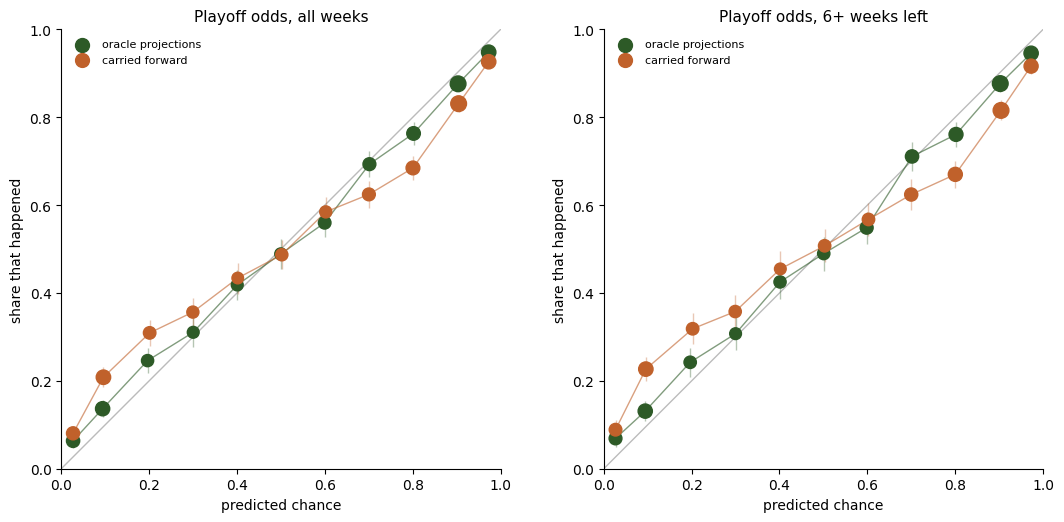

,p,y,n,se
playoff_oracle,,,,
"(0.01, 0.05]",0.027,0.063,993,0.008
"(0.05, 0.15]",0.094,0.137,1164,0.010
"(0.15, 0.25]",0.196,0.246,833,0.015
"(0.25, 0.35]",0.300,0.311,776,0.017
"(0.35, 0.45]",0.401,0.418,784,0.018
"(0.45, 0.55]",0.500,0.489,812,0.018
"(0.55, 0.65]",0.600,0.560,893,0.017
"(0.65, 0.75]",0.701,0.693,939,0.015
"(0.75, 0.85]",0.802,0.763,1056,0.013


In [9]:
import matplotlib.pyplot as plt
FIG = Path('..') / 'docs' / 'validation'
FIG.mkdir(parents=True, exist_ok=True)
BINS = np.array([0.01, 0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95, 0.99])

def reliability(df, pcol, ycol):
    d = df[(df[pcol] > 0.01) & (df[pcol] < 0.99)]
    b = pd.cut(d[pcol], BINS)
    g = d.groupby(b, observed=True).agg(p=(pcol, 'mean'), y=(ycol, 'mean'), n=(ycol, 'size'))
    g['se'] = np.sqrt(g.y * (1 - g.y) / g.n)
    return g

def rel_plot(ax, df, series, ycol, title):
    ax.plot([0, 1], [0, 1], color='#bbb', lw=1, zorder=0)
    for (label, col), color in zip(series.items(), ['#2d5a27', '#c0612b', '#4a6fa5']):
        g = reliability(df, col, ycol)
        ax.errorbar(g.p, g.y, yerr=1.96 * g.se, fmt='none', ecolor=color, alpha=0.35, lw=1)
        ax.scatter(g.p, g.y, s=8 + g.n / g.n.max() * 120, color=color, label=label, zorder=3)
        ax.plot(g.p, g.y, color=color, lw=1, alpha=0.6)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel('predicted chance'); ax.set_ylabel('share that happened'); ax.set_title(title, fontsize=11)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc='upper left')

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
rel_plot(axes[0], PO, {'oracle projections': 'playoff_oracle', 'carried forward': 'playoff_carry'}, 'made', 'Playoff odds, all weeks')
rel_plot(axes[1], PO[PO.weeks_left >= 6], {'oracle projections': 'playoff_oracle', 'carried forward': 'playoff_carry'}, 'made',
         'Playoff odds, 6+ weeks left')
plt.tight_layout(); plt.savefig(FIG / 'playoff_reliability.png', dpi=130); plt.show()
display(reliability(PO, 'playoff_oracle', 'made').round(3))

## Overconfident or underconfident? The volatility sweep

The same simulation with the team SD scaled by k. If the best k is above 1, the app's spread is too narrow, so its odds are too
extreme (overconfident); below 1, too wide. Common random numbers make the curve smooth, so small differences are real
differences between k values (not noise between runs), although the uncertainty about *which league-seasons* we happened to get is
still there (see the bootstrap on the best k below).

,brier,logloss,slope
k,,,
0.8,0.1088,0.3497,0.6977
1.0,0.1070,0.3375,0.7966
1.2,0.1063,0.3320,0.8894
1.4,0.1063,0.3303,0.9726
1.6,0.1066,0.3306,1.0474


best k by log loss across 300 league bootstraps: {1.0: 1, 1.2: 41, 1.4: 145, 1.6: 113}


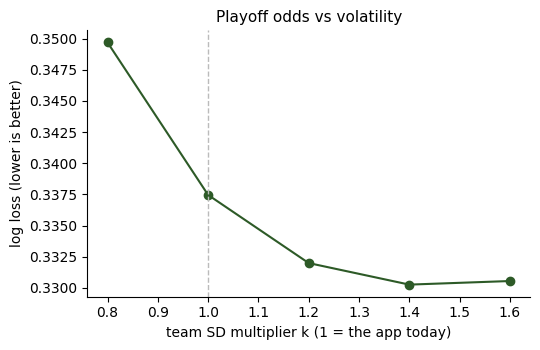

In [10]:
kcols = {k: ('playoff_oracle' if k == 1.0 else f'playoff_oracle_k{k}') for k in K_GRID}
sweep = pd.DataFrame([dict(k=k, brier=brier(PO[c], PO.made), logloss=logloss(PO[c], PO.made), slope=cal_fit(PO[c], PO.made)[1])
                      for k, c in kcols.items()]).set_index('k')
display(sweep.round(4))
rng = np.random.default_rng(1); keys = PO.lid.unique(); groups = {k: g for k, g in PO.groupby('lid')}
best = []
for _ in range(300):
    d = pd.concat([groups[k] for k in rng.choice(keys, len(keys))])
    best.append(min(K_GRID, key=lambda k: logloss(d[kcols[k]], d.made)))
print('best k by log loss across 300 league bootstraps:', pd.Series(best).value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(sweep.index, sweep.logloss, marker='o', color='#2d5a27')
ax.axvline(1.0, color='#bbb', lw=1, ls='--')
ax.set_xlabel('team SD multiplier k (1 = the app today)'); ax.set_ylabel('log loss (lower is better)')
ax.set_title('Playoff odds vs volatility', fontsize=11)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / 'playoff_volatility_sweep.png', dpi=130); plt.show()

## Why overconfident? Weekly noise vs a persistent strength error

Two facts point at the cause:

* the **records-only** run (no projections) is *under*confident (slope above 1), so the standings and schedule machinery is not the
  problem;
* the overconfidence is about the same with 12+ weeks left as with 1-3 left, and worse with the cruder carried-forward projections.

So the projections are treated as *exactly right* about each team for the rest of the season. In the simulation every week's error is
independent, so over ten weeks the errors average out and a team projected 5 points a week better than another looks almost certain
to finish ahead. In reality part of the error is about the team itself (an injury, a trade, a player who breaks out or falls off), and
that part persists. Inflating the weekly SD (k above) is the blunt fix; the **strength shock** τ is the targeted one, because it
leaves each single week's spread alone (the weekly matchup chance is checked separately in `live_winprob_calibration.ipynb`).

logloss                   slope                
event                 playoff   title   flush playoff   title   flush
projections variant                                                  
oracle      app today  0.3375  0.2374  0.2245  0.7966  0.7195  0.7395
            SD x 1.4   0.3303  0.2339  0.2187  0.9726  0.8741  0.9303
            tau 4      0.3343  0.2357  0.2232  0.8569  0.7616  0.7782
            tau 8      0.3326  0.2336  0.2210  1.0107  0.8660  0.8831
            tau 12     0.3368  0.2329  0.2205  1.2114  1.0116  1.0265
carry       app today  0.3984  0.2626  0.2598  0.6642  0.5815  0.5571
            tau 4      0.3893  0.2593  0.2558  0.7154  0.6195  0.5897
            tau 8      0.3775  0.2541  0.2488  0.8452  0.7158  0.6742
            tau 12     0.3739  0.2513  0.2442  1.0156  0.8441  0.7887

,brier oracle tau8,brier oracle,slope oracle tau8,n
phase,,,,
1-3 weeks left,0.0556,0.0563,0.8903,3600.0
4-7 weeks left,0.0937,0.0947,0.9795,4800.0
8-11 weeks left,0.1263,0.1267,1.0249,4800.0
12+ weeks left,0.1493,0.1483,1.1359,3580.0


best tau for playoff odds (oracle): 8 | log-loss gain over the app 0.0048, 95% league-bootstrap CI -0.0020 to 0.0124


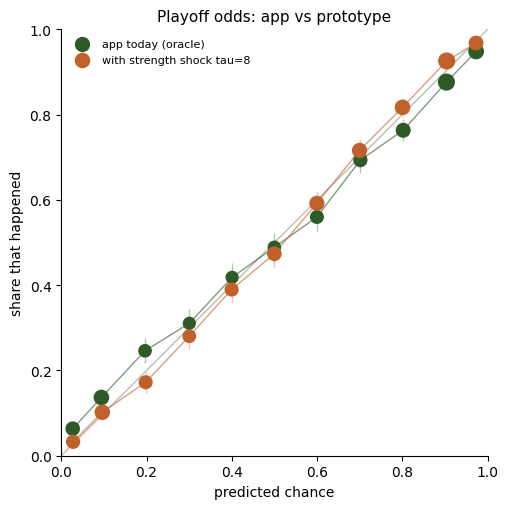

In [11]:
proto = []
for base in ('oracle', 'carry'):
    for label, suffix in [('app today', ''), ('SD x 1.4', '_k1.4'), ('tau 4', '_tau4'), ('tau 8', '_tau8'), ('tau 12', '_tau12')]:
        if base == 'carry' and suffix == '_k1.4': continue
        for ev, d, y in (('playoff', PO, 'made'), ('title', P, 'champ'), ('flush', P.dropna(subset=['flush']), 'flush')):
            c = f'{ev}_{base}{suffix}'
            yy = d[y].astype(float)
            proto.append(dict(projections=base, variant=label, event=ev, brier=brier(d[c], yy), logloss=logloss(d[c], yy), slope=cal_fit(d[c], yy)[1]))
proto = pd.DataFrame(proto)
display(proto.pivot_table(index=['projections', 'variant'], columns='event', values=['logloss', 'slope'], sort=False).round(4))

best_tau = min(TAU_GRID, key=lambda t: logloss(PO[f'playoff_oracle_tau{t}'], PO.made))
display(by_phase(PO, {f'oracle tau{best_tau}': f'playoff_oracle_tau{best_tau}', 'oracle': 'playoff_oracle'}, 'made').round(4))
gain = lambda d: logloss(d.playoff_oracle, d.made) - logloss(d[f'playoff_oracle_tau{best_tau}'], d.made)
rng = np.random.default_rng(2); keys = PO.lid.unique(); groups = {k: g for k, g in PO.groupby('lid')}
gains = [gain(pd.concat([groups[k] for k in rng.choice(keys, len(keys))])) for _ in range(500)]
print(f'best tau for playoff odds (oracle): {best_tau} | log-loss gain over the app {gain(PO):.4f}, '
      f'95% league-bootstrap CI {np.quantile(gains, 0.025):.4f} to {np.quantile(gains, 0.975):.4f}')

fig, ax = plt.subplots(figsize=(5.4, 5.2))
rel_plot(ax, PO, {'app today (oracle)': 'playoff_oracle', f'with strength shock tau={best_tau}': f'playoff_oracle_tau{best_tau}'}, 'made',
         'Playoff odds: app vs prototype')
plt.tight_layout(); plt.savefig(FIG / 'playoff_reliability_prototype.png', dpi=130); plt.show()

## Title and flush odds

Same scoring for the championship (one champion per league) and the flush (one per league that has at least two non-playoff teams).
These events are rarer (1 in 8 to 1 in 14), so the reliability bins are wider. Two baselines: the **records-only** simulation (same
machinery, no projections) and the **uniform** guess (1 / number of teams, what you would say knowing nothing).

title: 104 league-seasons


,n,brier,logloss,slope
model,,,,
oracle projections,16892,0.0698,0.2374,0.7195
carried forward,16892,0.0735,0.2626,0.5815
records only,16892,0.0743,0.2626,1.1113
uniform 1/teams,16892,0.0786,0.2928,NaN


flush: 103 league-seasons


,n,brier,logloss,slope
model,,,,
oracle projections,16780,0.0654,0.2245,0.7395
carried forward,16780,0.0725,0.2598,0.5571
records only,16780,0.0719,0.2516,1.3836
uniform 1/teams,16780,0.0784,0.2922,NaN


title volatility sweep:


,logloss,brier
k,,
0.8,0.2432,0.0714
1.0,0.2374,0.0698
1.2,0.2349,0.0690
1.4,0.2339,0.0687
1.6,0.2338,0.0686


flush volatility sweep:


,logloss,brier
k,,
0.8,0.2328,0.0670
1.0,0.2245,0.0654
1.2,0.2204,0.0647
1.4,0.2187,0.0644
1.6,0.2181,0.0643


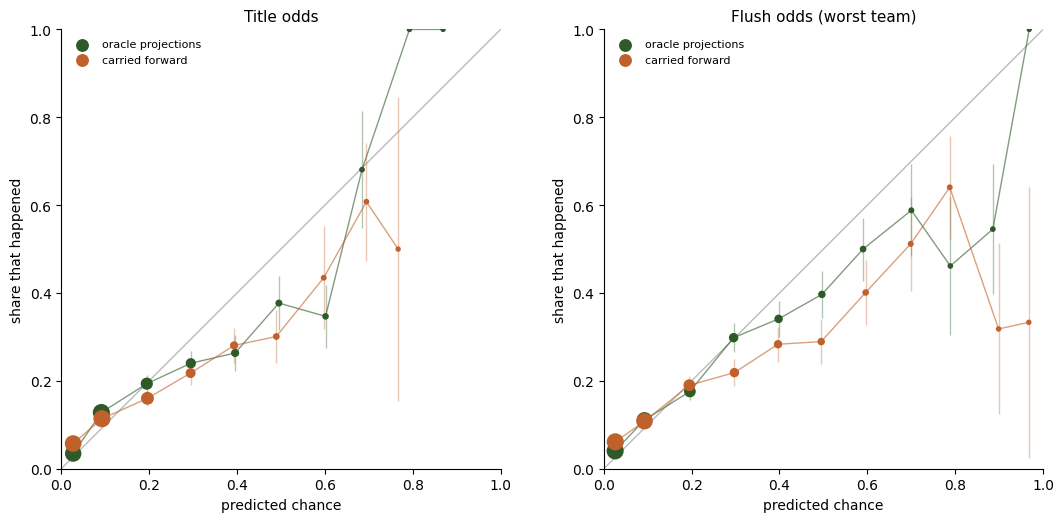

In [12]:
def event_table(df, ev, ycol):
    d = df.dropna(subset=[ycol, f'{ev}_oracle']).copy()
    d[ycol] = d[ycol].astype(float)
    d[f'{ev}_uniform'] = 1 / d.teams
    rows = []
    for name, c in {'oracle projections': f'{ev}_oracle', 'carried forward': f'{ev}_carry', 'records only': f'{ev}_records_only',
                    'uniform 1/teams': f'{ev}_uniform'}.items():
        s = scores(d, c, ycol) if name != 'uniform 1/teams' else dict(n=len(d), brier=brier(d[c], d[ycol]), logloss=logloss(d[c], d[ycol]), slope=np.nan)
        rows.append(dict(model=name, **s))
    return d, pd.DataFrame(rows).set_index('model')
TD, title_tab = event_table(P, 'title', 'champ')
FD, flush_tab = event_table(P, 'flush', 'flush')
print('title:', TD.lid.nunique(), 'league-seasons'); display(title_tab.round(4))
print('flush:', FD.lid.nunique(), 'league-seasons'); display(flush_tab.round(4))
for ev, d, y in (('title', TD, 'champ'), ('flush', FD, 'flush')):
    sw = pd.DataFrame([dict(k=k, logloss=logloss(d[f'{ev}_oracle' if k == 1.0 else f'{ev}_oracle_k{k}'], d[y]),
                            brier=brier(d[f'{ev}_oracle' if k == 1.0 else f'{ev}_oracle_k{k}'], d[y])) for k in K_GRID]).set_index('k')
    print(ev, 'volatility sweep:'); display(sw.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
rel_plot(axes[0], TD, {'oracle projections': 'title_oracle', 'carried forward': 'title_carry'}, 'champ', 'Title odds')
rel_plot(axes[1], FD, {'oracle projections': 'flush_oracle', 'carried forward': 'flush_carry'}, 'flush', 'Flush odds (worst team)')
plt.tight_layout(); plt.savefig(FIG / 'title_flush_reliability.png', dpi=130); plt.show()

## The owner's league: goon squad 2025

A single season is far too few outcomes to judge calibration, so this is a look at the story, not a test: the title chance the
app would have given the real champion and the real flush, week by week.

In [13]:
G = P[P.owner]
if len(G):
    champ_rid = G[G.champ].rid.iloc[0]; flush_rid = G[G.flush == True].rid.iloc[0] if (G.flush == True).any() else None
    story = G[G.rid == champ_rid].set_index('w')[['wins', 'rank', 'title_oracle', 'title_carry']].rename(columns=lambda c: 'champion ' + c)
    if flush_rid is not None:
        story = story.join(G[G.rid == flush_rid].set_index('w')[['wins', 'flush_oracle', 'flush_carry']].rename(columns=lambda c: 'flush ' + c))
    display(story.round(3))
    print('goon squad title log loss: oracle', round(logloss(G.title_oracle, G.champ), 4), '| uniform', round(logloss(1 / G.teams, G.champ), 4))

,champion wins,champion rank,champion title_oracle,champion title_carry
w,,,,
0,0.0,3,0.323,0.105
1,0.0,4,0.387,0.124
2,1.0,1,0.245,0.092
3,2.0,1,0.267,0.162
4,3.0,1,0.492,0.385
5,3.0,1,0.479,0.378
6,3.0,3,0.467,0.276
7,4.0,2,0.524,0.417
8,5.0,2,0.547,0.179


goon squad title log loss: oracle 0.1886 | uniform 0.3768


## What this says

* **The odds carry real information.** On 103 league-seasons (16,780 team-weeks) the app's playoff odds score a Brier of 0.107, against
  0.142 for the best standings-only baseline and 0.137 for the same simulation without projections. Title and flush odds also beat
  both the records-only simulation and the know-nothing 1/teams guess.
* **They are overconfident.** Calibration slope 0.80 for playoff odds (0.72 title, 0.74 flush), and about the same at every point of the
  season. Teams given 3% made it 6% of the time, teams given 10% made it 14%, and teams given 97% made it 95%. This is with the
  better-informed oracle projections; with carried-forward projections (no hindsight) the slope is 0.66, so the live app, which sits
  between the two, is likely somewhere around 0.7-0.8.
* **The cause is the team means, not the standings machinery.** With projections switched off the simulation is slightly
  *under*confident (slope 1.18). The overconfidence comes from treating each team's projected strength as exact for the rest of the
  season.
* **Fixes, prototyped:** multiplying the weekly team SD by 1.4 brings the playoff slope to 0.97 and gives the lowest log loss
  (0.330 vs 0.338). A persistent per-team strength shock with τ = 8 points gives slope 1.01 overall but over-corrects early in the
  season (1.14 with 12+ weeks left) and under-corrects late (0.89 with 1-3 left), so a fixed τ is not enough on its own. Both gains are
  small in log-loss terms (the τ = 8 gain's league-bootstrap interval includes zero), but the extreme odds (under 5%, over 95%) are the
  ones users quote, and they move most. Which fix is right depends on whether a *single week's* matchup chance is also overconfident;
  see `live_winprob_calibration.ipynb` and `score_correlation.ipynb`.
* **Caveats:** the extra leagues are mostly dynasty leagues of one group of players, reached through public example leagues; rosters
  are frozen at week `w`; and Sleeper's old future-week projections cannot be fetched, so the oracle/carried-forward pair brackets the
  app rather than replaying it exactly. The bracket port reproduces Sleeper's real champion in 103 of 104 leagues.